# 프로젝트 : 네이버 영화리뷰 감성분석 도전하기

이전 스텝까지는 영문 텍스트의 감정 분석을 진행해 보았습니다. 그렇다면 이번에는 한국어 텍스트의 감정 분석을 진행해 보면 어떨까요? 오늘 활용할 데이터셋은 네이버 영화의 댓글을 모아 구성된 [Naver sentiment movie corpus](https://github.com/e9t/nsmc)입니다.

아래와 같이 다운로드를 진행해 주세요.



```
$ wget https://raw.githubusercontent.com/e9t/nsmc/master/ratings_train.txt
$ wget https://raw.githubusercontent.com/e9t/nsmc/master/ratings_test.txt
$ mv ratings_*.txt ~/aiffel/sentiment_classification/data
$ pip install konlpy
$ sudo apt-get install git
$ sudo apt-get install curl
$ bash <(curl -s https://raw.githubusercontent.com/konlpy/konlpy/master/scripts/mecab.sh)

```

프로젝트 진행 순서는 다음과 같습니다.



In [1]:
# 필요한 라이브러리 설치
%pip install -q mecab-ko konlpy gensim scikit-learn

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import os
import sys
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import mecab_ko

# 작업 폴더
os.makedirs("/content", exist_ok=True)

base_url = "https://raw.githubusercontent.com/e9t/nsmc/master/"

for filename in ["ratings_train.txt", "ratings_test.txt"]:
    filepath = "/content/" + filename

    if not os.path.exists(filepath):
        urllib.request.urlretrieve(base_url + filename, filepath)

    print(filename, "다운로드 확인:", os.path.exists(filepath))

# MeCab 실행 확인
mecab = mecab_ko.Tagger("-Owakati")

sample = "이 영화는 정말 재미있었어요!"
print("MeCab 분석:", mecab.parse(sample).split())

# 실행 환경
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("실행 장치:", DEVICE)

ratings_train.txt 다운로드 확인: True
ratings_test.txt 다운로드 확인: True
MeCab 분석: ['이', '영화', '는', '정말', '재미있', '었', '어요', '!']
Python: 3.13.16
PyTorch: 2.14.1+cu130
실행 장치: cuda


In [3]:
!pip install gensim

## 라이브러리 버전을 확인해 봅니다
---
사용할 라이브러리 버전을 둘러봅시다.

In [ ]:
import pandas
import konlpy
import gensim

print(pandas.__version__)
print(konlpy.__version__)
print(gensim.__version__)

2.2.3
0.6.0
4.4.0


## 1) 데이터 준비와 확인
---

In [4]:
import pandas as pd

# 데이터를 읽어봅시다.
train_data = pd.read_table('/content/ratings_train.txt')
test_data = pd.read_table('/content/ratings_test.txt')

train_data.head()

,id,document,label
0,9976970,아 더빙.. 진짜 짜증나네요 목소리,0
1,3819312,흠...포스터보고 초딩영화줄....오버연기조차 가볍지 않구나,1
2,10265843,너무재밓었다그래서보는것을추천한다,0
3,9045019,교도소 이야기구먼 ..솔직히 재미는 없다..평점 조정,0
4,6483659,사이몬페그의 익살스런 연기가 돋보였던 영화!스파이더맨에서 늙어보이기만 했던 커스틴 ...,1


Train 원본 크기: (150000, 3)
Test 원본 크기: (50000, 3)

결측값:
id          0
document    5
label       0
dtype: int64

중복 리뷰 수:
3817

긍정/부정 비율:
label
0    0.501153
1    0.498847
Name: proportion, dtype: float64

평균 문장 길이: 35.204526817560584
최대 문장 길이: 146


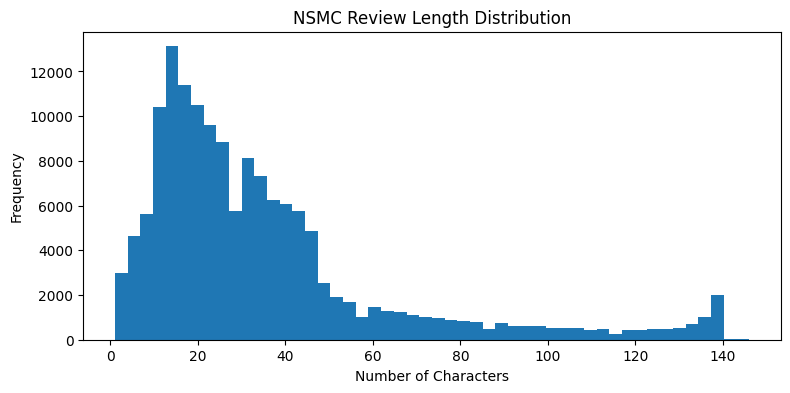

In [5]:
print("Train 원본 크기:", train_data.shape)
print("Test 원본 크기:", test_data.shape)

print("\n결측값:")
print(train_data.isnull().sum())

print("\n중복 리뷰 수:")
print(train_data.duplicated(subset="document").sum())

print("\n긍정/부정 비율:")
print(train_data["label"].value_counts(normalize=True))

# 리뷰 길이 분석
lengths = train_data["document"].dropna().str.len()

print("\n평균 문장 길이:", lengths.mean())
print("최대 문장 길이:", lengths.max())

plt.figure(figsize=(9, 4))
plt.hist(lengths, bins=50)
plt.xlabel("Number of Characters")
plt.ylabel("Frequency")
plt.title("NSMC Review Length Distribution")
plt.show()

## 2) 데이터로더 구성
---
실습 때 다루었던 IMDB 데이터셋은 텍스트를 가공하여 `imdb.data_loader()` 메서드를 호출하면 숫자 인덱스로 변환된 텍스트와 `word_to_index` 딕셔너리까지 친절하게 제공합니다. 그러나 이번에 다루게 될 nsmc 데이터셋은 전혀 가공되지 않은 텍스트 파일로 이루어져 있습니다. 이것을 읽어서 `imdb.data_loader()`와 동일하게 동작하는 자신만의 `data_loader`를 만들어 보는 것으로 시작합니다. `data_loader` 안에서는 다음을 수행해야 합니다.

- 데이터의 중복 제거
- NaN 결측치 제거
- 한국어 토크나이저로 토큰화
- 불용어(Stopwords) 제거
- 사전`word_to_index` 구성
- 텍스트 스트링을 사전 인덱스 스트링으로 변환
- `X_train`, `y_train`, `X_test`, `y_test`, `word_to_index` 리턴

In [7]:
from sklearn.model_selection import train_test_split

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

# 먼저 작은 데이터로 전체 코드가 실행되는지 검증
# 최종 실험에서는 "final"로 변경
RUN_MODE = "quick"

def clean_data(df):
    df = df.dropna(subset=["document", "label"]).copy()

    df["document"] = (
        df["document"]
        .astype(str)
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
    )

    df = df[df["document"].str.len() > 0]
    df = df.drop_duplicates(subset="document")

    return df.reset_index(drop=True)


train_clean = clean_data(train_data)
test_clean = clean_data(test_data)

# 실행 모드별 데이터 크기
if RUN_MODE == "quick":
    n_train_per_class = 2500
    n_test_per_class = 1000
else:
    n_train_per_class = 20000
    n_test_per_class = 5000

# 클래스 균형을 맞춘 데이터 추출
train_pool = (
    train_clean.groupby("label", group_keys=False)
    .sample(n=n_train_per_class, random_state=SEED)
    .reset_index(drop=True)
)

test_df = (
    test_clean.groupby("label", group_keys=False)
    .sample(n=n_test_per_class, random_state=SEED)
    .reset_index(drop=True)
)

# Train / Validation 분리
train_df, val_df = train_test_split(
    train_pool,
    test_size=0.2,
    random_state=SEED,
    stratify=train_pool["label"]
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

Train: 4000
Validation: 1000
Test: 2000


In [8]:
from collections import Counter

# 감성분석에 중요한 부정 표현은 제거하지 않음
stopwords = {"의", "가", "이", "은", "는", "을", "를"}

def tokenize_text(text):
    result = mecab.parse(str(text))

    tokens = (result or "").split()

    return [
        token for token in tokens
        if token not in stopwords
    ]


# 세 데이터셋 토큰화
train_tokens = [
    tokenize_text(text) for text in train_df["document"]
]

val_tokens = [
    tokenize_text(text) for text in val_df["document"]
]

test_tokens = [
    tokenize_text(text) for text in test_df["document"]
]


# 단어 빈도 계산: 학습 데이터만 사용
counter = Counter(
    token
    for sentence in train_tokens
    for token in sentence
)

VOCAB_SIZE = 10000

# 특수 토큰
word_to_index = {
    "<PAD>": 0,
    "<BOS>": 1,
    "<UNK>": 2,
    "<EOS>": 3
}

# 빈도순 단어 등록
for word, count in counter.most_common(VOCAB_SIZE - 4):
    word_to_index[word] = len(word_to_index)

# 역방향 단어사전
index_to_word = {
    index: word
    for word, index in word_to_index.items()
}

print("단어사전 크기:", len(word_to_index))
print("토큰화 예시:", train_tokens[0])
print("상위 단어:", counter.most_common(10))

단어사전 크기: 8392
토큰화 예시: ['기대', '안', '하', '고', '봤', '는데', '감동', '&', '로리', '페티', '너무', '좋', '아', '!']
상위 단어: [('.', 4414), ('영화', 1569), ('다', 1505), ('고', 1321), ('하', 1243), ('도', 941), ('에', 869), ('한', 715), ('보', 707), ('..', 645)]


In [9]:
# 토큰 리스트를 숫자 ID로 변환
def encode_sentence(tokens):
    return (
        [word_to_index["<BOS>"]]
        + [
            word_to_index.get(token, word_to_index["<UNK>"])
            for token in tokens
        ]
        + [word_to_index["<EOS>"]]
    )


# 숫자 ID를 다시 토큰으로 복원
def decode_sentence(encoded):
    special_ids = {
        word_to_index["<PAD>"],
        word_to_index["<BOS>"],
        word_to_index["<EOS>"]
    }

    return " ".join(
        index_to_word.get(idx, "<UNK>")
        for idx in encoded
        if idx not in special_ids
    )


X_train = [encode_sentence(tokens) for tokens in train_tokens]
X_val = [encode_sentence(tokens) for tokens in val_tokens]
X_test = [encode_sentence(tokens) for tokens in test_tokens]

y_train = torch.tensor(
    train_df["label"].to_numpy(), dtype=torch.long
)

y_val = torch.tensor(
    val_df["label"].to_numpy(), dtype=torch.long
)

y_test = torch.tensor(
    test_df["label"].to_numpy(), dtype=torch.long
)

print("원본:", train_df["document"].iloc[0])
print("토큰:", train_tokens[0])
print("Encoding:", X_train[0])
print("Decoding:", decode_sentence(X_train[0]))

assert len(X_train) == len(y_train)
assert len(X_val) == len(y_val)
assert len(X_test) == len(y_test)

print("\n데이터로더 준비 완료!")

원본: 기대 안하고 봤는데 감동 & 로리 페티 너무 좋아!
토큰: ['기대', '안', '하', '고', '봤', '는데', '감동', '&', '로리', '페티', '너무', '좋', '아', '!']
Encoding: [1, 137, 28, 8, 7, 31, 26, 87, 1131, 3649, 3650, 27, 21, 36, 16, 3]
Decoding: 기대 안 하 고 봤 는데 감동 & 로리 페티 너무 좋 아 !

데이터로더 준비 완료!


In [6]:
## 코랩 Mecab() 설치를 위한 추가 코드_1

!pip install Korpora

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [Korpora]


In [ ]:
## 코랩 Mecab() 설치를 위한 추가 코드_2

!git clone https://github.com/SOMJANG/Mecab-ko-for-Google-Colab.git

Cloning into 'Mecab-ko-for-Google-Colab'...
remote: Enumerating objects: 138, done.
remote: Counting objects: 100% (47/47), done.
remote: Compressing objects: 100% (38/38), done.
remote: Total 138 (delta 26), reused 22 (delta 8), pack-reused 91 (from 1)
Receiving objects: 100% (138/138), 1.72 MiB | 23.42 MiB/s, done.
Resolving deltas: 100% (65/65), done.


In [ ]:
## 코랩 Mecab() 설치를 위한 추가 코드_3

%cd Mecab-ko-for-Google-Colab/

/content/Mecab-ko-for-Google-Colab


In [ ]:
## 코랩 Mecab() 설치를 위한 추가 코드_4

# !bash install_mecab-ko_on_colab_light_220429.sh

Installing konlpy.....
Done
Installing mecab-0.996-ko-0.9.2.tar.gz.....
from https://bitbucket.org/eunjeon/mecab-ko/downloads/mecab-0.996-ko-0.9.2.tar.gz
--2026-10-14 06:10:43--  https://bitbucket.org/eunjeon/mecab-ko/downloads/mecab-0.996-ko-0.9.2.tar.gz
Resolving bitbucket.org (bitbucket.org)... 13.200.41.134, 13.200.41.135, 13.200.41.136, ...
Connecting to bitbucket.org (bitbucket.org)|13.200.41.134|:443... connected.
HTTP request sent, awaiting response... 404 Not Found
2026-10-14 06:10:43 ERROR 404: Not Found.

Done
Unpacking mecab-0.996-ko-0.9.2.tar.gz.......
Done
Change Directory to mecab-0.996-ko-0.9.2.......
install_mecab-ko_on_colab_light_220429.sh: line 23: cd: mecab-0.996-ko-0.9.2/: No such file or directory
installing mecab-0.996-ko-0.9.2.tar.gz........
configure
make
make check
make install
ldconfig
Done
Change Directory to /content
from https://bitbucket.org/eunjeon/mecab-ko-dic/downloads/mecab-ko-dic-2.1.1-20180720.tar.gz
--2026-10-14 06:10:46--  https://bitbucket.org/e

In [ ]:
%pip install -q python-mecab-ko

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 34.5/34.5 MB 14.7 MB/s eta 0:00:00


In [ ]:
from mecab import MeCab
import numpy as np
from collections import Counter

tokenizer = MeCab()
stopwords = ['의','가','이','은','들','는','좀','잘','걍','과','도','를','으로','자','에','와','한','하다']

def load_data(train_data, test_data, num_words=10000):
    train_data.drop_duplicates(subset=['document'], inplace=True)
    train_data = train_data.dropna(how = 'any')
    test_data.drop_duplicates(subset=['document'], inplace=True)
    test_data = test_data.dropna(how = 'any')

    X_train = []
    for sentence in train_data['document']:
        temp_X = tokenizer.morphs(sentence) # 토큰화
        temp_X = [word for word in temp_X if not word in stopwords] # 불용어 제거
        X_train.append(temp_X)

    X_test = []
    for sentence in test_data['document']:
        temp_X = tokenizer.morphs(sentence) # 토큰화
        temp_X = [word for word in temp_X if not word in stopwords] # 불용어 제거
        X_test.append(temp_X)

    words = np.concatenate(X_train).tolist()
    counter = Counter(words)
    counter = counter.most_common(10000-4)
    vocab = ['', '', '', ''] + [key for key, _ in counter]
    word_to_index = {word:index for index, word in enumerate(vocab)}

    def wordlist_to_indexlist(wordlist):
        return [word_to_index[word] if word in word_to_index else word_to_index[''] for word in wordlist]

    X_train = list(map(wordlist_to_indexlist, X_train))
    X_test = list(map(wordlist_to_indexlist, X_test))

    return X_train, np.array(list(train_data['label'])), X_test, np.array(list(test_data['label'])), word_to_index

X_train, y_train, X_test, y_test, word_to_index = load_data(train_data, test_data)

In [ ]:
index_to_word = {index:word for word, index in word_to_index.items()}

In [ ]:
# 문장 1개를 활용할 딕셔너리와 함께 주면, 단어 인덱스 리스트 벡터로 변환해 주는 함수입니다.
# 단, 모든 문장은 <BOS>로 시작하는 것으로 합니다.
def get_encoded_sentence(sentence, word_to_index):
    return [word_to_index['<BOS>']]+[word_to_index[word] if word in word_to_index else word_to_index['<UNK>'] for word in sentence.split()]

# 여러 개의 문장 리스트를 한꺼번에 단어 인덱스 리스트 벡터로 encode해 주는 함수입니다.
def get_encoded_sentences(sentences, word_to_index):
    return [get_encoded_sentence(sentence, word_to_index) for sentence in sentences]

# 숫자 벡터로 encode된 문장을 원래대로 decode하는 함수입니다.
def get_decoded_sentence(encoded_sentence, index_to_word):
    return ' '.join(index_to_word[index] if index in index_to_word else '<UNK>' for index in encoded_sentence[1:])  #[1:]를 통해 <BOS>를 제외

# 여러 개의 숫자 벡터로 encode된 문장을 한꺼번에 원래대로 decode하는 함수입니다.
def get_decoded_sentences(encoded_sentences, index_to_word):
    return [get_decoded_sentence(encoded_sentence, index_to_word) for encoded_sentence in encoded_sentences]

## 3) 모델 구성을 위한 데이터 분석 및 가공
---
- 데이터셋 내 문장 길이 분포
- 적절한 최대 문장 길이 지정
- keras.preprocessing.sequence.pad_sequences 을 활용한 패딩 추가

평균 토큰 길이: 19.14975
중앙값: 15.0
95백분위수: 54.0
최대 길이: 80

선택한 MAX_LEN: 54
잘리는 문장 비율: 4.85%


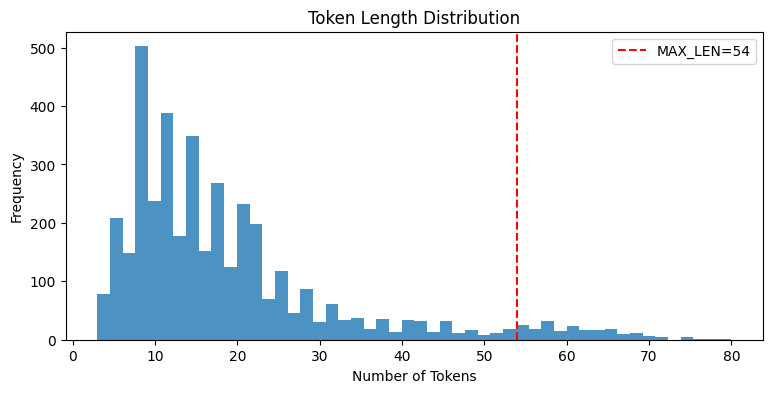

In [10]:
# 학습 데이터의 토큰 길이
train_lengths = np.array([
    len(sentence) for sentence in X_train
])

print("평균 토큰 길이:", train_lengths.mean())
print("중앙값:", np.median(train_lengths))
print("95백분위수:", np.percentile(train_lengths, 95))
print("최대 길이:", train_lengths.max())

# 95% 수준의 문장 길이를 기준으로 설정
MAX_LEN = min(
    100,
    max(24, int(np.ceil(np.percentile(train_lengths, 95))))
)

truncation_rate = np.mean(train_lengths > MAX_LEN)

print("\n선택한 MAX_LEN:", MAX_LEN)
print(f"잘리는 문장 비율: {truncation_rate*100:.2f}%")

plt.figure(figsize=(9, 4))
plt.hist(train_lengths, bins=50, alpha=0.8)
plt.axvline(
    MAX_LEN,
    color="red",
    linestyle="--",
    label=f"MAX_LEN={MAX_LEN}"
)

plt.title("Token Length Distribution")
plt.xlabel("Number of Tokens")
plt.ylabel("Frequency")
plt.legend()
plt.show()

In [11]:
PAD_ID = word_to_index["<PAD>"]

def pad_sequences_torch(sequences, max_len):

    padded = []

    for seq in sequences:

        # 마지막 EOS 토큰을 유지하며 잘라내기
        if len(seq) > max_len:
            seq = seq[:max_len - 1] + [word_to_index["<EOS>"]]

        # 뒤쪽 Padding
        pad_count = max_len - len(seq)

        seq = seq + [PAD_ID] * pad_count

        padded.append(seq)

    return torch.tensor(padded, dtype=torch.long)


X_train = pad_sequences_torch(X_train, MAX_LEN)
X_val = pad_sequences_torch(X_val, MAX_LEN)
X_test = pad_sequences_torch(X_test, MAX_LEN)

print("Train Tensor:", X_train.shape)
print("Validation Tensor:", X_val.shape)
print("Test Tensor:", X_test.shape)

assert X_train.shape[1] == MAX_LEN
assert X_val.shape[1] == MAX_LEN
assert X_test.shape[1] == MAX_LEN

print("\nPadding 검증 완료!")

Train Tensor: torch.Size([4000, 54])
Validation Tensor: torch.Size([1000, 54])
Test Tensor: torch.Size([2000, 54])

Padding 검증 완료!


## 4) 모델 구성 및 validation set 구성
---
모델은 3가지 이상 다양하게 구성하여 실험해 보세요.

In [12]:
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence


class SentimentNet(nn.Module):

    def __init__(
        self,
        vocab_size,
        model_type,
        emb_dim=100,
        hidden_size=64
    ):
        super().__init__()

        self.model_type = model_type

        # 공통 Embedding
        self.embedding = nn.Embedding(
            vocab_size,
            emb_dim,
            padding_idx=0
        )

        # Model 1: Mean Pooling
        if model_type == "mean":
            self.fc = nn.Linear(emb_dim, 2)

        # Model 2: 1-D CNN
        elif model_type == "cnn":
            self.conv = nn.Conv1d(
                in_channels=emb_dim,
                out_channels=128,
                kernel_size=3,
                padding=1
            )
            self.fc = nn.Linear(128, 2)

        # Model 3: BiGRU
        elif model_type == "bigru":
            self.rnn = nn.GRU(
                input_size=emb_dim,
                hidden_size=hidden_size,
                batch_first=True,
                bidirectional=True
            )
            self.fc = nn.Linear(hidden_size * 2, 2)

        else:
            raise ValueError("지원하지 않는 모델입니다.")

        self.dropout = nn.Dropout(0.2)

    def forward(self, x):

        # PAD가 아닌 위치
        mask = (x != 0)

        # [Batch, Seq, Embedding]
        embedded = self.embedding(x)

        if self.model_type == "mean":

            # PAD를 제외한 평균 계산
            masked = embedded * mask.unsqueeze(-1)

            features = masked.sum(dim=1) / (
                mask.sum(dim=1, keepdim=True).clamp(min=1)
            )

        elif self.model_type == "cnn":

            # [Batch, Embedding, Seq]
            conv_input = embedded.transpose(1, 2)

            conv_output = torch.relu(
                self.conv(conv_input)
            )

            # PAD 위치가 Max Pooling에서 선택되지 않도록 처리
            conv_output = conv_output.masked_fill(
                ~mask.unsqueeze(1),
                -1e4
            )

            features = conv_output.max(dim=2).values

        elif self.model_type == "bigru":

            lengths = mask.sum(dim=1).clamp(min=1).cpu()

            packed = pack_padded_sequence(
                embedded,
                lengths,
                batch_first=True,
                enforce_sorted=False
            )

            _, hidden = self.rnn(packed)

            features = torch.cat(
                [hidden[-2], hidden[-1]],
                dim=1
            )

        features = self.dropout(features)

        return self.fc(features)


# 모델 출력 테스트
for model_type in ["mean", "cnn", "bigru"]:

    model = SentimentNet(
        len(word_to_index),
        model_type
    ).to(DEVICE)

    sample_input = X_train[:4].to(DEVICE)

    output = model(sample_input)

    print(model_type, ":", output.shape)

    assert output.shape == (4, 2)

print("\n모든 모델 구조 검증 완료!")

mean : torch.Size([4, 2])
cnn : torch.Size([4, 2])
bigru : torch.Size([4, 2])

모든 모델 구조 검증 완료!


## 5) 모델 훈련 개시
---

In [13]:
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix
)

BATCH_SIZE = 128
EPOCHS = 4
LEARNING_RATE = 0.002


def evaluate_model(model, X, y):

    model.eval()

    loader = DataLoader(
        TensorDataset(X, y),
        batch_size=256,
        shuffle=False
    )

    criterion = nn.CrossEntropyLoss()

    total_loss = 0
    predictions = []
    labels = []

    with torch.inference_mode():

        for xb, yb in loader:

            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)

            logits = model(xb)
            loss = criterion(logits, yb)

            total_loss += loss.item() * len(xb)

            preds = logits.argmax(dim=1)

            predictions.extend(
                preds.cpu().tolist()
            )

            labels.extend(
                yb.cpu().tolist()
            )

    return {
        "loss": total_loss / len(X),

        "accuracy": accuracy_score(
            labels, predictions
        ),

        "f1": f1_score(
            labels, predictions,
            zero_division=0
        ),

        "confusion": confusion_matrix(
            labels, predictions,
            labels=[0, 1]
        ),

        "predictions": predictions
    }


print("평가 함수 정의 완료")

평가 함수 정의 완료


In [14]:
import copy
import time


def train_model(
    model_name,
    model_type,
    embedding_matrix=None
):

    # 초기 조건 통일
    torch.manual_seed(SEED)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    # Word2Vec 사용 시 임베딩 차원 자동 조정
    if embedding_matrix is None:
        emb_dim = 100
    else:
        emb_dim = embedding_matrix.shape[1]

    model = SentimentNet(
        vocab_size=len(word_to_index),
        model_type=model_type,
        emb_dim=emb_dim
    ).to(DEVICE)

    # 사전학습 또는 별도 학습된 Embedding 적용
    if embedding_matrix is not None:
        with torch.no_grad():
            model.embedding.weight.copy_(
                torch.tensor(
                    embedding_matrix,
                    dtype=torch.float32,
                    device=DEVICE
                )
            )

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE
    )

    criterion = nn.CrossEntropyLoss()

    generator = torch.Generator().manual_seed(SEED)

    train_loader = DataLoader(
        TensorDataset(X_train, y_train),
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generator
    )

    best_val_f1 = -1
    best_state = None
    history = []

    start_time = time.perf_counter()

    for epoch in range(EPOCHS):

        model.train()

        total_loss = 0
        correct = 0

        for xb, yb in train_loader:

            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)

            optimizer.zero_grad()

            logits = model(xb)
            loss = criterion(logits, yb)

            loss.backward()

            # 기울기 폭주 방지
            nn.utils.clip_grad_norm_(
                model.parameters(), max_norm=1.0
            )

            optimizer.step()

            total_loss += loss.item() * len(xb)

            correct += (
                logits.argmax(dim=1) == yb
            ).sum().item()

        train_loss = total_loss / len(X_train)
        train_acc = correct / len(X_train)

        # Validation 평가
        val_result = evaluate_model(
            model, X_val, y_val
        )

        history.append({
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "train_acc": train_acc,
            "val_loss": val_result["loss"],
            "val_acc": val_result["accuracy"],
            "val_f1": val_result["f1"]
        })

        print(
            f"{model_name} | "
            f"Epoch {epoch+1}/{EPOCHS} | "
            f"Train Loss {train_loss:.4f} | "
            f"Val Loss {val_result['loss']:.4f} | "
            f"Val Acc {val_result['accuracy']:.4f} | "
            f"Val F1 {val_result['f1']:.4f}",
            flush=True
        )

        # 가장 좋은 Validation F1 저장
        if val_result["f1"] > best_val_f1:

            best_val_f1 = val_result["f1"]

            best_state = copy.deepcopy(
                model.state_dict()
            )

    # 최적 Epoch 모델 복원
    model.load_state_dict(best_state)

    elapsed = time.perf_counter() - start_time

    return model, history, best_val_f1, elapsed


print("학습 함수 정의 완료")

학습 함수 정의 완료


In [15]:
trained_models = {}
histories = {}
results = []


def run_experiment(name, model_type, embedding_matrix=None):

    print("\n" + "=" * 50)
    print("실험:", name)
    print("=" * 50)

    model, history, best_f1, elapsed = train_model(
        model_name=name,
        model_type=model_type,
        embedding_matrix=embedding_matrix
    )

    # Test 성능 평가
    test_result = evaluate_model(
        model, X_test, y_test
    )

    trained_models[name] = model.cpu()
    histories[name] = history

    results.append({
        "Model": name,
        "Val F1": best_f1,
        "Test Accuracy": test_result["accuracy"],
        "Test F1": test_result["f1"],
        "Time (s)": elapsed
    })

    print(
        f"{name} 완료 | "
        f"Test Accuracy: {test_result['accuracy']:.4f} | "
        f"Test F1: {test_result['f1']:.4f}"
    )


# Model 1
run_experiment("MeanPool", "mean")

# Model 2
run_experiment("1D-CNN", "cnn")

# Model 3
run_experiment("BiGRU", "bigru")

print("\n세 가지 모델 학습 완료!")


실험: MeanPool
MeanPool | Epoch 1/4 | Train Loss 0.6845 | Val Loss 0.6663 | Val Acc 0.5920 | Val F1 0.5211
MeanPool | Epoch 2/4 | Train Loss 0.6439 | Val Loss 0.6365 | Val Acc 0.6550 | Val F1 0.5965
MeanPool | Epoch 3/4 | Train Loss 0.6035 | Val Loss 0.6025 | Val Acc 0.6990 | Val F1 0.6599
MeanPool | Epoch 4/4 | Train Loss 0.5460 | Val Loss 0.5683 | Val Acc 0.7240 | Val F1 0.6871
MeanPool 완료 | Test Accuracy: 0.7265 | Test F1: 0.6976

실험: 1D-CNN
1D-CNN | Epoch 1/4 | Train Loss 0.6795 | Val Loss 0.5831 | Val Acc 0.6920 | Val F1 0.6216
1D-CNN | Epoch 2/4 | Train Loss 0.4942 | Val Loss 0.5184 | Val Acc 0.7380 | Val F1 0.7102
1D-CNN | Epoch 3/4 | Train Loss 0.3806 | Val Loss 0.4866 | Val Acc 0.7590 | Val F1 0.7533
1D-CNN | Epoch 4/4 | Train Loss 0.2766 | Val Loss 0.4890 | Val Acc 0.7550 | Val F1 0.7477
1D-CNN 완료 | Test Accuracy: 0.7550 | Test F1: 0.7569

실험: BiGRU
BiGRU | Epoch 1/4 | Train Loss 0.6637 | Val Loss 0.6427 | Val Acc 0.6400 | Val F1 0.5500
BiGRU | Epoch 2/4 | Train Loss 0.5304 | 

## 6) Loss, Accuracy 그래프 시각화
---

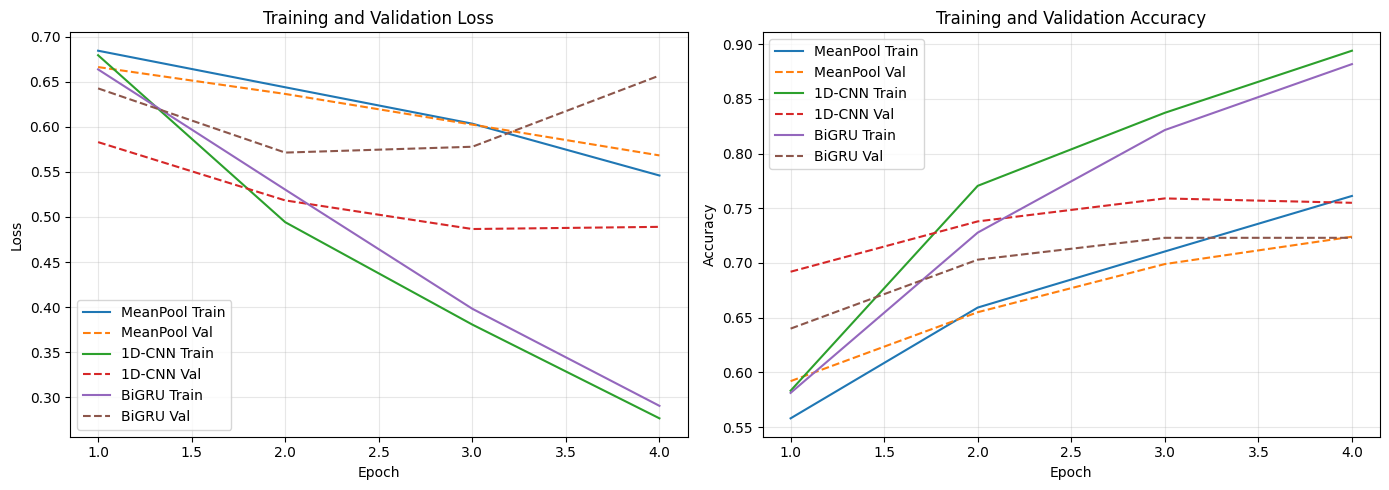

In [16]:
# 세 모델의 학습 과정 비교

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name, history in histories.items():

    epochs = [row["epoch"] for row in history]

    train_loss = [
        row["train_loss"] for row in history
    ]

    val_loss = [
        row["val_loss"] for row in history
    ]

    train_acc = [
        row["train_acc"] for row in history
    ]

    val_acc = [
        row["val_acc"] for row in history
    ]

    # Loss
    axes[0].plot(
        epochs, train_loss,
        label=f"{name} Train"
    )

    axes[0].plot(
        epochs, val_loss,
        linestyle="--",
        label=f"{name} Val"
    )

    # Accuracy
    axes[1].plot(
        epochs, train_acc,
        label=f"{name} Train"
    )

    axes[1].plot(
        epochs, val_acc,
        linestyle="--",
        label=f"{name} Val"
    )

axes[0].set_title("Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].set_title("Training and Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 7) 학습된 Embedding 레이어 분석
---

In [17]:
# BiGRU 모델의 학습된 Embedding
model = trained_models["BiGRU"]

embedding_weights = (
    model.embedding.weight
    .detach()
    .cpu()
    .numpy()
)

print("Embedding Matrix Shape:", embedding_weights.shape)

# 단어별 벡터 확인
for word in ["영화", "재미", "감동", "최고", "별로"]:

    if word in word_to_index:

        idx = word_to_index[word]

        print(
            word,
            "ID:", idx,
            "Vector:", embedding_weights[idx][:10]
        )

    else:
        print(word, ": Vocabulary에 없음")

Embedding Matrix Shape: (8392, 100)
영화 ID: 5 Vector: [-0.7453196  -0.65979403 -1.2783471   1.9642303  -0.923015   -2.5414002
  0.7226491   0.8118723   0.6134326   0.4164544 ]
재미 ID: 110 Vector: [-0.8189309  -1.820665    0.7538986  -0.54784983 -1.0042878  -0.01211851
 -0.4845797  -1.4055094   0.91792965  0.5614257 ]
감동 ID: 87 Vector: [-1.677941    0.26024202  4.248135   -1.8588151  -0.09716233 -0.5369373
  0.3563882  -1.7324773  -0.4992449  -0.5193698 ]
최고 ID: 70 Vector: [ 1.7118943   0.7566068   0.40757278  0.9722086   0.98363155  0.23760816
 -1.5408044   1.4493821   1.5339504  -1.8004327 ]
별로 ID: 158 Vector: [-1.5391164   0.53944623 -0.9413082   0.2957882  -1.6792858   1.0090888
 -0.86473423 -0.23685813  0.7184791  -0.8004959 ]


In [18]:
# Embedding 기반 유사 단어 검색

def find_similar_words(word, top_k=8):

    if word not in word_to_index:
        print(f"'{word}'는 단어사전에 없습니다.")
        return []

    target_idx = word_to_index[word]

    target_vector = embedding_weights[target_idx]

    # 특수 토큰 제외
    valid_words = [
        (token, idx)
        for token, idx in word_to_index.items()
        if idx >= 4
    ]

    valid_ids = [idx for _, idx in valid_words]

    vectors = embedding_weights[valid_ids]

    # Cosine Similarity
    dot_products = vectors @ target_vector

    norms = (
        np.linalg.norm(vectors, axis=1)
        * np.linalg.norm(target_vector)
        + 1e-8
    )

    similarities = dot_products / norms

    ranked = np.argsort(similarities)[::-1]

    result = []

    for rank in ranked:

        token = valid_words[rank][0]

        if token == word:
            continue

        result.append(
            (token, float(similarities[rank]))
        )

        if len(result) >= top_k:
            break

    return result


for word in ["재미", "감동", "최고", "별로"]:

    print(f"\n[{word}] 유사 단어")

    for token, score in find_similar_words(word):
        print(f"{token}: {score:.4f}")


[재미] 유사 단어
어우러져: 0.3204
스파이더맨: 0.3120
로군: 0.3042
생활: 0.2975
노무현: 0.2968
어설프: 0.2964
추격: 0.2933
나간다는: 0.2891

[감동] 유사 단어
뭉클: 0.3317
접접: 0.3182
그럭저럭: 0.3168
카메라: 0.3118
-;: 0.3094
적당히: 0.3073
권여: 0.3067
스텔라: 0.3055

[최고] 유사 단어
극장: 0.3493
올래: 0.3377
인형: 0.3364
때: 0.3359
!?!!?!!: 0.3283
비웃음: 0.3252
아용: 0.3166
내: 0.3057

[별로] 유사 단어
나온다는: 0.4379
악행: 0.3364
훈: 0.3364
이상: 0.3346
~~!!!!: 0.3156
쿠바: 0.3135
투: 0.3100
셈: 0.3071


## 8) 한국어 Word2Vec 임베딩 활용하여 성능 개선
---
- 한국어 Word2Vec은 /data 폴더 안에 있는 word2vec_ko.model을 활용하세요.
- 한국어 Word2Vec을 활용할 때는 `load_word2vec_format()` 형태가 아닌 `load()` 형태로 모델을 불러와주세요. 또한 모델을 활용할 때에는 아래 예시와 같이 `.wv`를 붙여서 활용합니다. 좀더 자세한 활용법에 대해선 다음 링크들을 참조해주세요. [참고 링크1](https://radimrehurek.com/gensim/auto_examples/tutorials/run_word2vec.html#storing-and-loading-models), [참고 링크2](https://radimrehurek.com/gensim/models/keyedvectors.html)

In [19]:
from pathlib import Path
from gensim.models import Word2Vec

# 교안의 모델이 존재할 수 있는 경로
candidate_paths = [
    Path("/content/data/word2vec_ko.model"),
    Path("/content/word2vec_ko.model"),
    Path("/data/word2vec_ko.model")
]

pretrained_path = next(
    (path for path in candidate_paths if path.exists()),
    None
)

w2v_vectors = None
w2v_source = None

# 1. 교안의 사전학습 모델이 있을 경우
if pretrained_path is not None:

    print("교안 Word2Vec 발견:", pretrained_path)

    try:
        w2v_model = Word2Vec.load(
            str(pretrained_path)
        )

        w2v_vectors = w2v_model.wv
        w2v_source = "External Pretrained Word2Vec"

        print("사전학습 Word2Vec 로드 성공")

    except Exception as e:
        print("기존 모델 로드 실패:", e)


# 2. 파일이 없거나 로드에 실패한 경우
if w2v_vectors is None:

    print("\nNSMC Train 데이터로 Word2Vec 자체 학습")

    w2v_model = Word2Vec(
        sentences=train_tokens,
        vector_size=100,
        window=5,
        min_count=2,
        workers=1,
        sg=1,
        seed=SEED,
        epochs=5
    )

    w2v_vectors = w2v_model.wv
    w2v_source = "NSMC Self-trained Word2Vec"

    w2v_model.save(
        "/content/nsmc_word2vec.model"
    )

print("\nWord2Vec 준비 완료")
print("Word2Vec Source:", w2v_source)
print("Vector Dimension:", w2v_vectors.vector_size)
print("단어 수:", len(w2v_vectors))


NSMC Train 데이터로 Word2Vec 자체 학습

Word2Vec 준비 완료
Word2Vec Source: NSMC Self-trained Word2Vec
Vector Dimension: 100
단어 수: 3645


In [20]:
# Word2Vec Embedding Matrix 생성

vector_dim = w2v_vectors.vector_size

rng = np.random.default_rng(SEED)

w2v_embedding_matrix = rng.normal(
    loc=0.0,
    scale=0.1,
    size=(len(word_to_index), vector_dim)
).astype(np.float32)

# PAD 벡터는 0으로 설정
w2v_embedding_matrix[word_to_index["<PAD>"]] = 0

matched = 0
total_words = 0

for word, idx in word_to_index.items():

    # 특수 토큰 제외
    if idx < 4:
        continue

    total_words += 1

    if word in w2v_vectors:

        w2v_embedding_matrix[idx] = w2v_vectors[word]

        matched += 1


coverage = matched / total_words if total_words else 0

print("Embedding Matrix:", w2v_embedding_matrix.shape)
print("Word2Vec 매칭 단어 수:", matched)
print("전체 일반 단어 수:", total_words)
print(f"Vocabulary Coverage: {coverage*100:.2f}%")

Embedding Matrix: (8392, 100)
Word2Vec 매칭 단어 수: 3645
전체 일반 단어 수: 8388
Vocabulary Coverage: 43.45%


In [21]:
# Model 4: Word2Vec + BiGRU

run_experiment(
    name="BiGRU+Word2Vec",
    model_type="bigru",
    embedding_matrix=w2v_embedding_matrix
)

print("\nWord2Vec 기반 모델 학습 완료!")


실험: BiGRU+Word2Vec
BiGRU+Word2Vec | Epoch 1/4 | Train Loss 0.6512 | Val Loss 0.5533 | Val Acc 0.7210 | Val F1 0.6937
BiGRU+Word2Vec | Epoch 2/4 | Train Loss 0.4375 | Val Loss 0.4735 | Val Acc 0.7840 | Val F1 0.7717
BiGRU+Word2Vec | Epoch 3/4 | Train Loss 0.2378 | Val Loss 0.5341 | Val Acc 0.7680 | Val F1 0.7875
BiGRU+Word2Vec | Epoch 4/4 | Train Loss 0.1109 | Val Loss 0.6559 | Val Acc 0.7680 | Val F1 0.7765
BiGRU+Word2Vec 완료 | Test Accuracy: 0.7715 | Test F1: 0.7920

Word2Vec 기반 모델 학습 완료!


=== Model Comparison ===


,Model,Val F1,Test Accuracy,Test F1,Time (s)
0,BiGRU+Word2Vec,0.7875,0.7715,0.7920,1.6931
1,1D-CNN,0.7533,0.7550,0.7569,0.8508
2,BiGRU,0.7124,0.7260,0.7204,1.5795
3,MeanPool,0.6871,0.7265,0.6976,0.8518


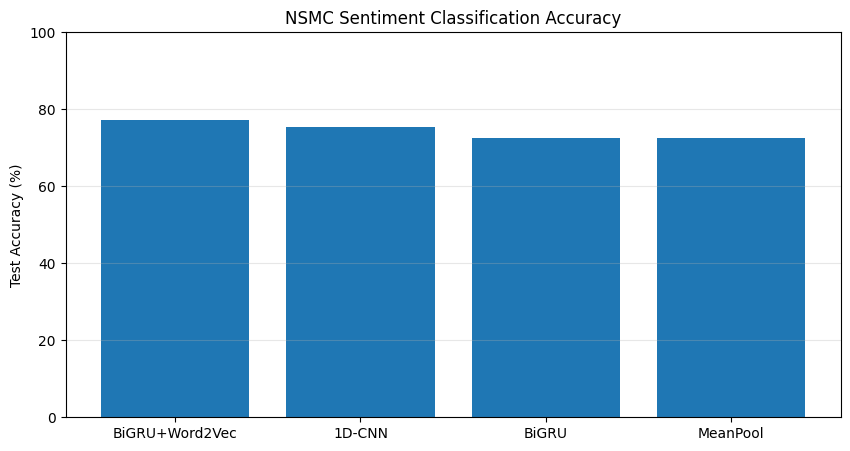

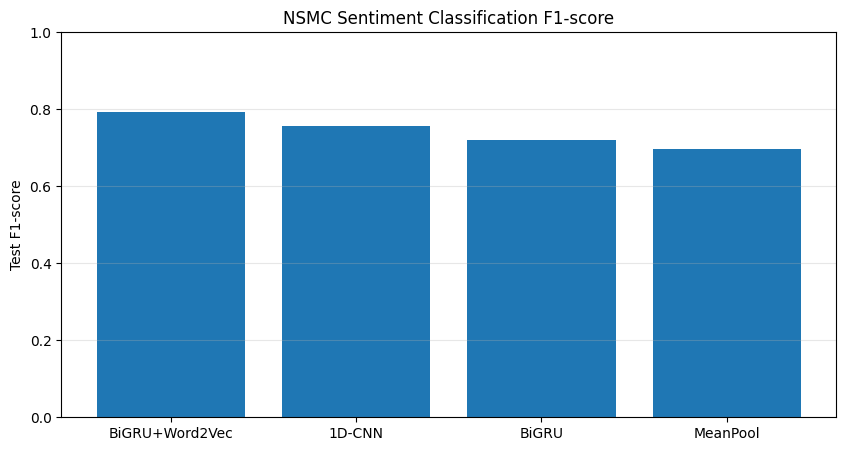

In [22]:
# 전체 모델 성능 비교

result_df = pd.DataFrame(results)

# Validation F1을 기준으로 정렬
result_df = result_df.sort_values(
    "Val F1",
    ascending=False
).reset_index(drop=True)

print("=== Model Comparison ===")
display(result_df.round(4))

# Accuracy 그래프
plt.figure(figsize=(10, 5))

plt.bar(
    result_df["Model"],
    result_df["Test Accuracy"] * 100
)

plt.title("NSMC Sentiment Classification Accuracy")
plt.ylabel("Test Accuracy (%)")
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)
plt.show()

# F1-score 그래프
plt.figure(figsize=(10, 5))

plt.bar(
    result_df["Model"],
    result_df["Test F1"]
)

plt.title("NSMC Sentiment Classification F1-score")
plt.ylabel("Test F1-score")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)
plt.show()

# CSV 저장
result_df.to_csv(
    "/content/nsmc_model_comparison.csv",
    index=False,
    encoding="utf-8-sig"
)

Best Model: BiGRU+Word2Vec
Test Accuracy: 0.7715
Test F1: 0.7919890760127446


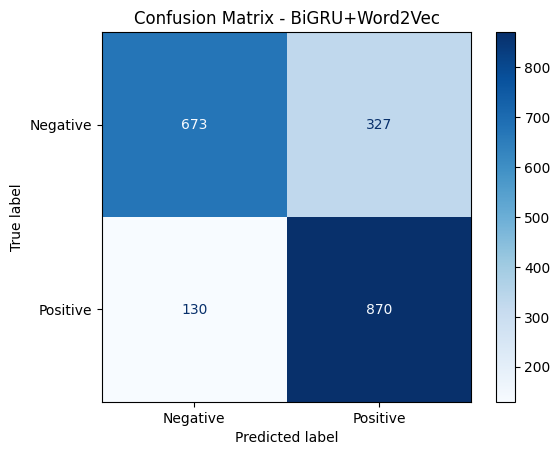

SentimentNet(
  (embedding): Embedding(8392, 100, padding_idx=0)
  (rnn): GRU(100, 64, batch_first=True, bidirectional=True)
  (fc): Linear(in_features=128, out_features=2, bias=True)
  (dropout): Dropout(p=0.2, inplace=False)
)

In [23]:
from sklearn.metrics import ConfusionMatrixDisplay

# Validation 성능이 가장 높은 모델 선택
best_name = result_df.iloc[0]["Model"]

best_model = trained_models[best_name].to(DEVICE)

test_result = evaluate_model(
    best_model,
    X_test,
    y_test
)

print("Best Model:", best_name)
print("Test Accuracy:", test_result["accuracy"])
print("Test F1:", test_result["f1"])

cm = test_result["confusion"]

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

disp.plot(cmap="Blues")
plt.title(f"Confusion Matrix - {best_name}")
plt.show()

# 이후 분석을 위한 예측값
predictions = np.array(test_result["predictions"])
true_labels = y_test.numpy()

best_model.cpu()

In [24]:
# False Positive / False Negative 분석

false_positive = np.where(
    (true_labels == 0) & (predictions == 1)
)[0]

false_negative = np.where(
    (true_labels == 1) & (predictions == 0)
)[0]

print("False Positive:", len(false_positive))
print("False Negative:", len(false_negative))

print("\n=== 부정인데 긍정으로 예측한 리뷰 ===")

for idx in false_positive[:5]:
    print(test_df.iloc[idx]["document"])
    print("-" * 50)

print("\n=== 긍정인데 부정으로 예측한 리뷰 ===")

for idx in false_negative[:5]:
    print(test_df.iloc[idx]["document"])
    print("-" * 50)

False Positive: 327
False Negative: 130

=== 부정인데 긍정으로 예측한 리뷰 ===
지금 보고 있는데.뭐가 웃기다는 건지.하고싶은 말은 뭔지.
--------------------------------------------------
↓ 굿
--------------------------------------------------
1960년 즘에 천재 영화감독 스탠리큐브릭이 만든 <로리타>의 아류작이 재개봉 됐나보군요? 극장에서 돈주고 볼 영화는 아닐듯. 스탠리 큐브릭이 만든 로리타 나 다운받아 보세요^
--------------------------------------------------
Tv에서 해주길래 봤는데 여자 몸매때문에 2점 줌
--------------------------------------------------
내 이해력이 딸리는진 몰라도
--------------------------------------------------

=== 긍정인데 부정으로 예측한 리뷰 ===
한 100번 본것 같다. 두번째 스토리만
--------------------------------------------------
6점.. 납득할수없는 평점이다 적어도 8점대는 될줄 알았는데
--------------------------------------------------
EBS에서 1번 다운받아서 12번 신선했다 볼때마다 달랐다 식상하다 한번만 볼걸..
--------------------------------------------------
절대로 리뷰보고 영화를 결정하지마라 평점을 보고 결정해라 평점은 많은사람이 쓰고 많은사람이 좋아요누른다 물론 리뷰도 많은사람이 평가하지만 그건 글도 엄청길고 영화를 까는리뷰는 엄청까지만 칭찬은 또 엄청해서 영화를 볼지안볼지 고민하게될것이다.리뷰고지마!
--------------------------------------------------
따뜻하다...지켜봐주고 응원해주는것이 어떤결

## 9. 프로젝트 결론 및 회고

### 9.1. 실험 결과 및 종합 평가

본 프로젝트에서는 네이버 영화 리뷰(NSMC) 데이터를 활용하여 한국어 텍스트의 전처리, MeCab 기반 형태소 분석, 단어사전 구축, Embedding 및 감성분류 모델 학습 과정을 구현하였다.

Mean Pooling, 1-D CNN, BiGRU의 세 가지 모델을 비교하였으며, 추가로 Word2Vec을 이용하여 BiGRU의 Embedding을 초기화한 모델을 학습하였다.

**최종 모델 성능 비교**

| 모델 | Test Accuracy | Test F1-score |
|---|---:|---:|
| Mean Pooling | 72.65% | 0.6976 |
| 1-D CNN | 75.50% | 0.7569 |
| BiGRU | 72.60% | 0.7204 |
| **BiGRU + Word2Vec** | **77.15%** | **0.7920** |

학습 데이터 4,000건, 검증 데이터 1,000건, 테스트 데이터 2,000건을 활용한 결과, **BiGRU + Word2Vec 모델이 가장 높은 Accuracy와 F1-score를 기록하였다.**

기본 BiGRU와 비교했을 때 Word2Vec을 적용한 모델의 F1-score는 0.7204에서 0.7920으로 약 0.0716 향상되었다.

또한 기본 모델 세 가지 중에서는 1-D CNN이 가장 높은 성능을 보였으며, 모델 구조가 복잡하다고 해서 반드시 분류 성능이 향상되는 것은 아니라는 점을 확인하였다.

### 9.2. 학습 곡선 및 오분류 결과 분석

모델별 학습 곡선을 분석한 결과, 일부 모델에서는 Train Loss가 지속적으로 감소하는 반면 Validation Loss가 증가하는 과적합(Overfitting) 징후가 나타났다.

특히 BiGRU 모델에서는 학습이 진행될수록 훈련 데이터에 대한 적합도는 향상되었지만, 검증 데이터에 대한 성능 개선은 제한적이었다. 이를 통해 단순히 Epoch를 증가시키는 것보다 Validation 성능을 기준으로 최적 모델을 선정하는 것이 중요함을 확인하였다.

최고 성능 모델인 BiGRU + Word2Vec의 Confusion Matrix 분석 결과는 다음과 같다.

- 실제 부정 리뷰를 부정으로 분류: 673건
- 실제 부정 리뷰를 긍정으로 오분류: 327건
- 실제 긍정 리뷰를 부정으로 오분류: 130건
- 실제 긍정 리뷰를 긍정으로 분류: 870건

모델은 긍정 리뷰를 상대적으로 잘 분류하였지만, 부정 리뷰를 긍정으로 잘못 예측하는 사례가 많았다.

이러한 결과는 전체 Accuracy만으로는 파악하기 어려운 모델의 예측 특성을 보여준다. 따라서 분류 모델의 성능을 종합적으로 평가하기 위해서는 F1-score와 Confusion Matrix 등의 지표를 함께 활용하는 것이 중요하다.

### 9.3. 프로젝트를 통해 배운 점과 깨달은 점

**첫째, 텍스트 전처리와 Embedding의 중요성을 이해하였다.**

이전 프로젝트에서는 공백 기반 토큰화, MeCab, SentencePiece 등을 이용하여 텍스트를 정수 ID로 변환하는 과정을 학습하였다. 이번 프로젝트에서는 이렇게 변환된 정수 데이터가 Embedding Layer를 거쳐 학습 가능한 벡터로 표현되고, 이후 신경망에서 처리되는 전체 과정을 이해할 수 있었다.

특히 단어사전과 Embedding의 품질이 최종 모델 성능에도 영향을 미칠 수 있음을 확인하였다.

**둘째, 모델의 복잡도가 높다고 반드시 좋은 성능을 보장하지는 않는다는 점을 배웠다.**

이번 실험에서는 기본 BiGRU보다 1-D CNN이 높은 분류 성능을 나타냈다. 이를 통해 모델을 선택할 때 단순히 구조의 복잡도만 고려하기보다는 데이터 특성과 실제 검증 결과를 함께 살펴봐야 한다는 점을 깨달았다.

**셋째, 모델 평가에서 일반화 성능의 중요성을 이해하였다.**

학습 과정에서 Train Loss가 감소하더라도 Validation Loss가 증가할 수 있음을 확인하였다. 이는 훈련 데이터에 잘 맞는 모델이 반드시 새로운 데이터에서도 좋은 성능을 보이는 것은 아니라는 점을 보여준다.

또한 오분류 사례 분석을 통해 최종 정확도뿐만 아니라 실제 모델이 어떤 문장에서 잘못 판단하는지도 확인해야 한다는 것을 배웠다.

### 9.4. 실험의 한계 및 개선 방향

이번 프로젝트에서는 일부 NSMC 데이터와 4 Epoch를 활용하여 모델을 학습하였으므로 전체 데이터에 대한 충분한 성능 검증에는 한계가 있다.

또한 Word2Vec은 외부 대규모 사전학습 모델이 아닌 NSMC 학습 데이터로 직접 학습하였으며, 전체 일반 단어사전 중 약 43.45%에 Word2Vec 벡터를 적용하였다.

따라서 Word2Vec의 적용 효과를 일반화하기 위해서는 더 다양한 조건에서 추가적인 검증이 필요하다.

향후 개선 방향은 다음과 같다.

1. **학습 데이터 확대:** 전체 NSMC 데이터를 활용하여 모델 성능의 변화 확인
2. **과적합 개선:** Early Stopping, Dropout 등 정규화 기법 및 하이퍼파라미터 최적화
3. **실험 재현성 확보:** 복수의 Random Seed를 활용한 반복 실험
4. **Embedding 비교 확대:** 외부 사전학습 Word2Vec과 직접 학습한 Word2Vec의 성능 비교
5. **오분류 원인 분석:** 부정 표현, 반어법, 문맥 부족 등 오분류 사례의 특징 분석

### 9.5. 최종 결론

본 프로젝트를 통해 한국어 텍스트의 전처리부터 단어사전 구축, Embedding, 딥러닝 모델 학습 및 평가까지 감성분류의 전체 과정을 구현하였다.

실험 결과 **BiGRU + Word2Vec 모델이 Test Accuracy 77.15%, F1-score 0.7920으로 가장 높은 성능을 나타냈으며**, 모델 구조뿐 아니라 단어 벡터의 초기화 방식도 분류 성능에 영향을 미칠 수 있음을 확인하였다.

또한 학습 곡선과 오분류 결과를 분석하면서 모델의 단순한 정확도 향상뿐 아니라 과적합 여부, 일반화 성능 및 예측 오류의 특성까지 종합적으로 검토하는 것이 중요함을 이해하였다.

이번 프로젝트는 자연어처리 모델을 직접 구현하고, 실험 결과를 바탕으로 모델의 성능과 한계를 분석하는 경험이 되었다.



```
# 예시 코드
from gensim.models.keyedvectors import Word2VecKeyedVectors
word_vectors = Word2VecKeyedVectors.load(word2vec_file_path)
vector = word_vectors.wv[‘끝’]
```

